# Industry Expectations Across IT Career Clusters: Data Preparation and Cluster-Wise Exploratory Analysis

**Scope.** This notebook filters, cleans and analyses IT job postings for five career clusters: *Software Engineering*, *DevOps/Cloud Engineering*, *Cybersecurity*, *Networking & Infrastructure*, and *Data & AI Engineering*. Because the data contain no salary information, the analysis is built on job titles, cluster membership, required experience, job descriptions and the skills/technologies field.

**Pipeline**

1. Load the data, standardise column names and resolve the schema.
2. Assign each record to a career cluster and keep only the defined clusters.
3. Drop records with a missing cluster label or missing experience value (where an experience field exists).
4. Convert `experience_years` to numeric and remove IQR outliers within each cluster.
5. Tokenise the multi-value skills field and normalise skill names.
6. Produce four sets of charts (cluster size, experience, top skills per cluster, tool-frequency and specialisation), each saved as a 300 dpi PNG.

## 0. Data audit notes (read before running)

The dataset `IT_Job_Dataset_SriLanka_20000.csv` has **six columns**: `Job Role`, `Job Title`, `Student Qualification`, `Student Skills`, `Job Description`, and `experience_years`. Against the variables named in the research design:

| Variable in the design | Present in file | Handling in this notebook |
|---|---|---|
| career cluster label | no (only `Job Role`) | derived from `Job Role` through an explicit, editable mapping |
| job titles | yes (`Job Title`) | summarised per cluster |
| job descriptions | yes (`Job Description`) | term frequencies per cluster |
| required skills / technologies | `Student Skills` (skills held by a candidate profile) | used as the skills field; interpret as skills *observed* per role |
| `experience_years` | **yes** | cleaned via numeric parser, IQR outlier removal, and analysed in Chart 2 |
| posting date | **no** | the temporal part of Chart 4 runs only if a date column exists |

`experience_years` is fully integrated, enabling the complete cleaning pipeline, cluster-wise IQR outlier removal, distribution boxplots, and Kruskal-Wallis non-parametric hypothesis testing.


## 1. Setup and configuration

In [1]:
import re
import textwrap
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from scipy import stats
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False

warnings.filterwarnings("ignore")

# ----- paths -----------------------------------------------------------
DATA_PATH = Path("IT_Job_Dataset_SriLanka_20000.csv") if Path("IT_Job_Dataset_SriLanka_20000.csv").exists() else Path("../IT_Job_Dataset_SriLanka_20000.csv")
OUTPUT_DIR = Path("outputs/charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ----- figure settings -------------------------------------------------
DPI = 300
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ----- research scope --------------------------------------------------
CLUSTERS = [
    "Software Engineering",
    "DevOps/Cloud Engineering",
    "Cybersecurity",
    "Networking & Infrastructure",
    "Data & AI Engineering",
]
CLUSTER_COLORS = dict(zip(CLUSTERS, sns.color_palette("colorblind", len(CLUSTERS))))

# Used only when the file has no explicit cluster column.
# Roles absent from this mapping are treated as outside the research scope.
ROLE_TO_CLUSTER = {
    "software engineer":          "Software Engineering",
    "web developer":              "Software Engineering",
    "mobile app developer":       "Software Engineering",
    "devops engineer":            "DevOps/Cloud Engineering",
    "cybersecurity analyst":      "Cybersecurity",
    "network administrator":      "Networking & Infrastructure",
    "it support specialist":      "Networking & Infrastructure",
    "data analyst":               "Data & AI Engineering",
    "machine learning engineer":  "Data & AI Engineering",
}

# Spellings of cluster labels that may appear in an explicit cluster column.
CLUSTER_LABEL_ALIASES = {
    "softwareengineering": "Software Engineering",
    "devopscloudengineering": "DevOps/Cloud Engineering",
    "devopscloud": "DevOps/Cloud Engineering",
    "devops": "DevOps/Cloud Engineering",
    "cloudengineering": "DevOps/Cloud Engineering",
    "cybersecurity": "Cybersecurity",
    "networkinginfrastructure": "Networking & Infrastructure",
    "networkinfrastructure": "Networking & Infrastructure",
    "networkingandinfrastructure": "Networking & Infrastructure",
    "dataaiengineering": "Data & AI Engineering",
    "dataandaiengineering": "Data & AI Engineering",
    "dataai": "Data & AI Engineering",
}

# Candidate column names (after snake_case standardisation), in priority order.
COLUMN_ALIASES = {
    "cluster":    ["career_cluster", "cluster", "it_cluster", "job_cluster"],
    "role":       ["job_role", "role", "job_title", "title"],
    "experience": ["experience_years", "required_experience", "experience", "years_of_experience"],
    "description": ["job_description", "description", "job_summary"],
    "date":       ["posted_date", "posting_date", "date_posted", "date", "year"],
    "skills":     ["required_skills", "skills", "required_technologies", "technologies", "student_skills"],
}

# Surface forms of the same skill that should be merged.
SKILL_ALIASES = {
    "nodejs": "Node.js", "node": "Node.js", "node js": "Node.js", "node.js": "Node.js",
    "powerbi": "Power BI", "power-bi": "Power BI", "power bi": "Power BI",
    "js": "JavaScript", "javascript": "JavaScript",
    "k8s": "Kubernetes",
    "c sharp": "C#", "csharp": "C#",
    "amazon web services": "AWS",
    "reactjs": "React", "react.js": "React",
    "angularjs": "Angular",
    "ms excel": "Excel", "microsoft excel": "Excel",
    "postgres": "PostgreSQL",
}

# Grouping of tools used in Chart 4 (unlisted tools fall under "Other").
TOOL_CATEGORIES = {
    "Python": "Programming languages", "Java": "Programming languages",
    "JavaScript": "Programming languages", "C#": "Programming languages",
    "SQL": "Data & analytics",
    "Excel": "Data & analytics", "Power BI": "Data & analytics",
    "HTML": "Web technologies", "CSS": "Web technologies", "React": "Web technologies",
    "Angular": "Web technologies", "Node.js": "Web technologies",
    "Docker": "Cloud & DevOps", "Kubernetes": "Cloud & DevOps",
    "AWS": "Cloud & DevOps", "Linux": "Cloud & DevOps",
}
ENTRY_MAX_YEARS = 2     # experience <= 2 years -> entry level
SENIOR_MIN_YEARS = 5    # experience >= 5 years -> senior
TOP_N = 5

IQR_K = 1.5              # Tukey fence multiplier
DROP_DUPLICATES = False  # postings carry no unique identifier, so exact duplicates cannot be told apart from distinct postings

## 2. Data loading and schema resolution

In [2]:
def to_snake(name: str) -> str:
    return re.sub(r"[^0-9a-z]+", "_", str(name).strip().lower()).strip("_")


def resolve(df: pd.DataFrame, key: str):
    """Return the first column of `df` matching the aliases registered for `key`."""
    for candidate in COLUMN_ALIASES[key]:
        if candidate in df.columns:
            return candidate
    return None


raw = pd.read_csv(DATA_PATH)
raw.columns = [to_snake(c) for c in raw.columns]

print(f"Records: {len(raw):,} | Columns: {raw.shape[1]}")
print("Columns:", list(raw.columns))
print(f"Exact duplicate rows: {raw.duplicated().sum():,}")
display(raw.head())
display(raw.isna().sum().rename("missing_values").to_frame())

Records: 20,000 | Columns: 6
Columns: ['job_role', 'job_title', 'student_qualification', 'student_skills', 'job_description', 'experience_years']
Exact duplicate rows: 4


,job_role,job_title,student_qualification,student_skills,job_description,experience_years
0,Machine Learning Engineer,AI Engineer,Diploma in Software Engineering,"Python, Kubernetes, JavaScript",Designs models and algorithms to solve real-wo...,4+ years
1,IT Support Specialist,Technical Support Engineer,BSc in Information Systems,"Kubernetes, CSS, Node.js",Provides technical assistance and support for ...,1
2,Business Analyst,System Analyst,BSc in Information Systems,"Node.js, C#, Kubernetes, Angular, JavaScript",Bridges business needs with technical implemen...,2.6
3,Software Engineer,Full Stack Engineer,BSc in Information Systems,"SQL, CSS, React, C#, AWS","Responsible for designing, developing, and mai...",2-5 years
4,Network Administrator,Infrastructure Support,HND in IT,"Power BI, Docker, React, CSS, Kubernetes, SQL","Manages internal networks, ensuring uptime and...",2


,missing_values
job_role,0
job_title,0
student_qualification,0
student_skills,0
job_description,0
experience_years,198


In [3]:
cluster_col = resolve(raw, "cluster")
role_col    = resolve(raw, "role")
exp_col     = resolve(raw, "experience")
desc_col    = resolve(raw, "description")
date_col    = resolve(raw, "date")
skills_col  = resolve(raw, "skills")

schema = pd.Series({
    "cluster": cluster_col, "role": role_col, "experience": exp_col,
    "description": desc_col, "date": date_col, "skills": skills_col,
}, name="resolved_column").fillna("NOT FOUND")
display(schema.to_frame())

HAS_EXPERIENCE = exp_col is not None
HAS_DATE = date_col is not None

if skills_col is None:
    raise ValueError("No skills column found; add the column name to COLUMN_ALIASES['skills'].")
if cluster_col is None and role_col is None:
    raise ValueError("Neither a cluster nor a role column was found.")

if not HAS_EXPERIENCE:
    print("NOTE: no experience column found -> experience cleaning and Chart 2 will be skipped.")
if not HAS_DATE:
    print("NOTE: no posting-date column found -> the temporal panel of Chart 4 will be skipped.")

,resolved_column
cluster,NOT FOUND
role,job_role
experience,experience_years
description,job_description
date,NOT FOUND
skills,student_skills


NOTE: no posting-date column found -> the temporal panel of Chart 4 will be skipped.


## 3. Cluster-specific filtering

Each record is assigned to one of the five defined clusters, either from an explicit cluster column or, when none exists, from `Job Role` via `ROLE_TO_CLUSTER`. Records whose cluster is missing or outside the defined set are removed. Rows with a missing experience value are then dropped, if an experience field exists. A row-count ledger is kept so every exclusion is traceable.

In [4]:
df = raw.copy()
ledger = [("Raw records", len(df))]

if DROP_DUPLICATES:
    df = df.drop_duplicates()
    ledger.append(("After removing exact duplicates", len(df)))

def label_key(x):
    return re.sub(r"[^a-z]", "", str(x).lower())

# --- assign career cluster ---------------------------------------------
if cluster_col is not None:
    source = df[cluster_col]
    df["career_cluster"] = source.map(
        lambda v: CLUSTER_LABEL_ALIASES.get(label_key(v)) if pd.notna(v) else np.nan
    )
    n_missing = int(source.isna().sum())
    cluster_source = f"explicit column '{cluster_col}'"
else:
    source = df[role_col]
    df["career_cluster"] = source.map(
        lambda v: ROLE_TO_CLUSTER.get(str(v).strip().lower()) if pd.notna(v) else np.nan
    )
    n_missing = int(source.isna().sum())
    cluster_source = f"derived from '{role_col}' via ROLE_TO_CLUSTER"
print("Cluster assignment:", cluster_source)

# --- drop missing cluster, then out-of-scope ------------------------
df = df[source.notna().reindex(df.index)]
ledger.append(("After dropping missing cluster/role label", len(df)))

out_of_scope = df["career_cluster"].isna()
print("Out-of-scope categories removed:")
print(df.loc[out_of_scope, cluster_col or role_col].value_counts().to_string() or "  none")
df = df[~out_of_scope].copy()
ledger.append(("After keeping the five defined clusters", len(df)))

# --- drop missing experience (only where the field exists) ------------
if HAS_EXPERIENCE:
    df = df[df[exp_col].notna()]
    ledger.append(("After dropping missing experience", len(df)))

df["career_cluster"] = pd.Categorical(df["career_cluster"], categories=CLUSTERS, ordered=True)

Cluster assignment: derived from 'job_role' via ROLE_TO_CLUSTER
Out-of-scope categories removed:
job_role
Business Analyst    1985


## 4. Numeric conversion and IQR outlier removal

`experience_years` is converted to a number. Text such as `"2-4 years"` or `"5+ years"` is parsed, ranges are replaced by their midpoint, and negative values are treated as invalid.

Outliers are identified with Tukey's fences (Q1 − 1.5·IQR, Q3 + 1.5·IQR) computed **within each cluster**. Clusters differ in seniority profile, so a pooled fence would disproportionately flag legitimate observations from the more senior clusters.

In [5]:
def parse_numeric(value):
    """Convert messy numeric text to a float; ranges become midpoints."""
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float, np.integer, np.floating)):
        return float(value)
    text = str(value).lower().replace(",", "")
    text = re.sub(r"(?<=\d)\s*k\b", "000", text)          # 150k -> 150000
    numbers = [float(n) for n in re.findall(r"\d+(?:\.\d+)?", text)]
    return float(np.mean(numbers[:2])) if numbers else np.nan


def iqr_bounds(series: pd.Series, k: float = IQR_K):
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - k * spread, q3 + k * spread


def remove_iqr_outliers(frame: pd.DataFrame, columns, group_col="career_cluster", k=IQR_K):
    keep = pd.Series(True, index=frame.index)
    records = []
    for group, sub in frame.groupby(group_col, observed=True):
        for col in columns:
            lo, hi = iqr_bounds(sub[col], k)
            flagged = (sub[col] < lo) | (sub[col] > hi)
            keep.loc[sub.index[flagged]] = False
            records.append({"cluster": group, "variable": col, "lower_fence": round(lo, 2),
                            "upper_fence": round(hi, 2), "outliers": int(flagged.sum()), "n": len(sub)})
    return frame[keep].copy(), pd.DataFrame(records)


numeric_cols = []
if HAS_EXPERIENCE:
    df["experience_years"] = df[exp_col].map(parse_numeric)
    df.loc[df["experience_years"] < 0, "experience_years"] = np.nan
    numeric_cols.append("experience_years")

if numeric_cols:
    df = df.dropna(subset=numeric_cols)
    ledger.append(("After numeric conversion (unparseable/invalid removed)", len(df)))
    df, outlier_log = remove_iqr_outliers(df, numeric_cols)
    ledger.append(("After IQR outlier removal", len(df)))
    display(outlier_log)
else:
    print("No continuous variables available -> numeric conversion and IQR step skipped.")

,cluster,variable,lower_fence,upper_fence,outliers,n
0,Software Engineering,experience_years,-0.25,5.75,190,5877
1,DevOps/Cloud Engineering,experience_years,0.00,8.00,56,2027
2,Cybersecurity,experience_years,0.35,7.15,77,2002
3,Networking & Infrastructure,experience_years,-2.00,6.00,79,3827
4,Data & AI Engineering,experience_years,-1.00,7.00,81,4008


## 5. Tokenisation of the multi-value skills field

Skills are split on commas, semicolons and pipes (slashes are preserved so that entries such as `CI/CD` stay intact). Tokens are trimmed, whitespace is normalised, and spelling variants are merged through `SKILL_ALIASES` and a most-frequent-surface-form rule. Duplicate skills within one posting are counted once, so frequencies are the **share of postings in a cluster that mention a skill**.

In [6]:
def split_skills(cell):
    if pd.isna(cell):
        return []
    tokens = []
    for part in re.split(r"[,;|\n]+", str(cell)):
        part = re.sub(r"\s+", " ", part).strip(" .\t\"'[]()")
        if part:
            tokens.append(part)
    return tokens


df["_raw_tokens"] = df[skills_col].map(split_skills)

# most frequent surface form per case-insensitive key, then explicit aliases on top
surface = pd.Series([t for toks in df["_raw_tokens"] for t in toks])
canon = (surface.groupby(surface.str.lower())
                .agg(lambda s: s.value_counts().idxmax())
                .to_dict())
canon.update({k.lower(): v for k, v in SKILL_ALIASES.items()})

df["skills_list"] = df["_raw_tokens"].map(
    lambda toks: sorted({canon.get(t.lower(), t) for t in toks})
)
df["n_skills"] = df["skills_list"].map(len)

skills_long = (df[["career_cluster", "skills_list"]]
               .explode("skills_list")
               .dropna(subset=["skills_list"])
               .rename(columns={"skills_list": "skill"}))

postings_with_skills = (df[df["n_skills"] > 0]
                        .groupby("career_cluster", observed=True).size())
skill_counts = (skills_long.groupby(["career_cluster", "skill"], observed=True)
                .size().rename("postings").reset_index())
cluster_totals = {str(k): int(v) for k, v in postings_with_skills.items()}
skill_counts["career_cluster"] = skill_counts["career_cluster"].astype(str)
skill_counts["share_pct"] = (skill_counts["postings"]
                             / skill_counts["career_cluster"].map(cluster_totals) * 100)

print(f"Distinct skills after normalisation: {skills_long['skill'].nunique()}")
print(f"Skills per posting: mean = {df['n_skills'].mean():.2f}, "
      f"min = {df['n_skills'].min()}, max = {df['n_skills'].max()}")
print(f"Postings with no parsable skills: {(df['n_skills'] == 0).sum()}")

Distinct skills after normalisation: 16
Skills per posting: mean = 4.49, min = 3, max = 6
Postings with no parsable skills: 0


### Data-preparation ledger

In [7]:
ledger_df = pd.DataFrame(ledger, columns=["step", "records_remaining"])
ledger_df["removed_in_step"] = (-ledger_df["records_remaining"].diff()).fillna(0).astype(int)
display(ledger_df)
ledger_df.to_csv(OUTPUT_DIR.parent / "data_preparation_ledger.csv", index=False)

df.drop(columns=["_raw_tokens"]).assign(skills_list=df["skills_list"].map("; ".join)) \
  .to_csv(OUTPUT_DIR.parent / "cleaned_cluster_dataset.csv", index=False)
print(f"Analysis sample: {len(df):,} records across {df['career_cluster'].nunique()} clusters")

,step,records_remaining,removed_in_step
0,Raw records,20000,0
1,After dropping missing cluster/role label,20000,0
2,After keeping the five defined clusters,18015,1985
3,After dropping missing experience,17838,177
4,After numeric conversion (unparseable/invalid ...,17741,97
5,After IQR outlier removal,17258,483


Analysis sample: 17,258 records across 5 clusters


## 6. Chart utilities

In [8]:
def save_figure(fig, filename: str):
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    print(f"Saved: {path}")
    alt = Path("outputscharts") / filename
    if Path("outputscharts").exists():
        fig.savefig(alt, dpi=DPI, bbox_inches="tight", facecolor="white")


def wrap(label: str, width: int = 16) -> str:
    return "\n".join(textwrap.wrap(label, width))


def slug(text: str) -> str:
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


## 7. Chart 1: Job count distribution across career clusters

Saved: outputs/charts/chart1_job_count_by_cluster.png


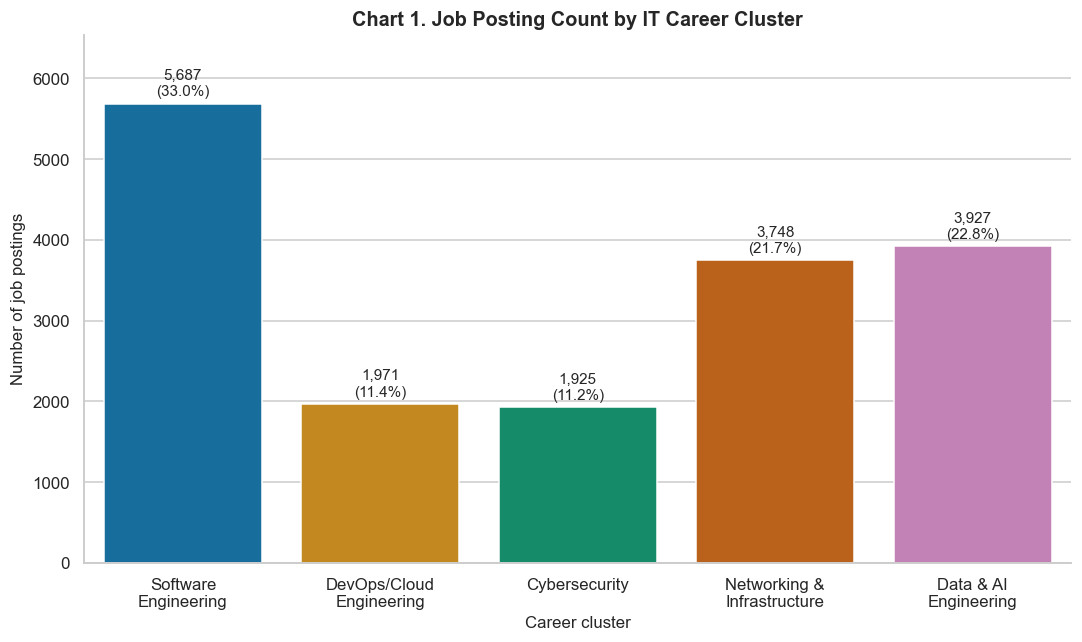

Chi-square goodness-of-fit against equal cluster sizes: chi2 = 2849.0, df = 4, p = 0


,postings,share_pct
career_cluster,,
Software Engineering,5687,32.95
DevOps/Cloud Engineering,1971,11.42
Cybersecurity,1925,11.15
Networking & Infrastructure,3748,21.72
Data & AI Engineering,3927,22.75


In [9]:
counts = df["career_cluster"].value_counts().reindex(CLUSTERS)
shares = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x="career_cluster", order=CLUSTERS, hue="career_cluster",
              hue_order=CLUSTERS, palette=CLUSTER_COLORS, legend=False, dodge=False, ax=ax)

for patch, c in zip(ax.patches, CLUSTERS):
    ax.annotate(f"{int(counts[c]):,}\n({shares[c]:.1f}%)",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")

ax.set_xticks(range(len(CLUSTERS)))
ax.set_xticklabels([wrap(c) for c in CLUSTERS])
ax.set_xlabel("Career cluster")
ax.set_ylabel("Number of job postings")
ax.set_title("Chart 1. Job Posting Count by IT Career Cluster")
ax.set_ylim(0, counts.max() * 1.15)
fig.tight_layout()
save_figure(fig, "chart1_job_count_by_cluster.png")
plt.show()

if HAS_SCIPY:
    chi2, p = stats.chisquare(counts.values)
    print(f"Chi-square goodness-of-fit against equal cluster sizes: chi2 = {chi2:.1f}, "
          f"df = {len(CLUSTERS) - 1}, p = {p:.3g}")
display(pd.DataFrame({"postings": counts, "share_pct": shares.round(2)}))

### Interpretation: Chart 1

Chart 1 shows how the analysed postings are distributed across the five clusters and therefore how much evidence each cluster contributes to later comparisons. **Software Engineering is the largest cluster (about 33% of the sample)**, followed by Data & AI Engineering (about 23%) and Networking & Infrastructure (about 22%). DevOps/Cloud Engineering and Cybersecurity are the smallest, at about 11% each.

This ordering is largely **a product of how clusters are defined**. Software Engineering pools three roles (software, web and mobile development), Networking & Infrastructure and Data & AI Engineering pool two roles each, and DevOps and Cybersecurity map to a single role each. Each underlying role has roughly 2,000 postings, so differences in cluster size reflect the number of roles grouped, not an observed difference in employer demand. The chi-square goodness-of-fit result is therefore not evidence of market imbalance. Cluster-size differences should not be read as demand differences unless the cluster mapping is justified independently, and the cluster definitions in the proposal should be reported alongside this chart. Because the smaller clusters still contain over 2,000 postings each, all five have enough observations for the within-cluster comparisons below.

## 8. Chart 2: Required experience distribution per cluster

Saved: outputs/charts/chart2_experience_by_cluster.png


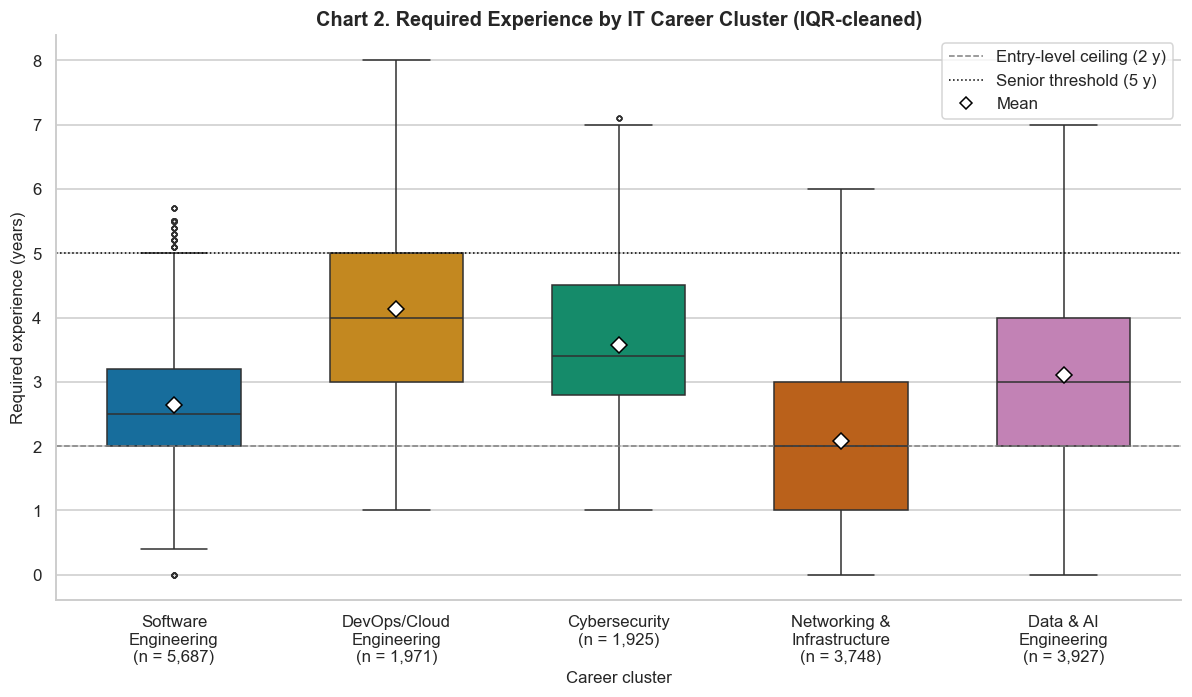

,count,mean,std,min,25%,50%,75%,max
career_cluster,,,,,,,,
Software Engineering,5687.0,2.64,1.07,0.0,2.0,2.5,3.2,5.7
DevOps/Cloud Engineering,1971.0,4.14,1.44,1.0,3.0,4.0,5.0,8.0
Cybersecurity,1925.0,3.58,1.32,1.0,2.8,3.4,4.5,7.1
Networking & Infrastructure,3748.0,2.08,1.16,0.0,1.0,2.0,3.0,6.0
Data & AI Engineering,3927.0,3.10,1.51,0.0,2.0,3.0,4.0,7.0


experience_years,Entry (<= 2 y),Mid (2-5 y),Senior (>= 5 y)
career_cluster,,,
Software Engineering,42.4,53.6,4.0
DevOps/Cloud Engineering,9.6,57.7,32.7
Cybersecurity,18.3,62.0,19.7
Networking & Infrastructure,64.8,32.0,3.2
Data & AI Engineering,32.1,51.7,16.2


Kruskal-Wallis across clusters: H = 3298.82, p = 0


In [10]:
if HAS_EXPERIENCE:
    fig, ax = plt.subplots(figsize=(11, 6.5))
    sns.boxplot(data=df, x="career_cluster", y="experience_years", order=CLUSTERS,
                hue="career_cluster", hue_order=CLUSTERS, palette=CLUSTER_COLORS, legend=False,
                showmeans=True, width=0.6, fliersize=3, dodge=False,
                meanprops={"marker": "D", "markerfacecolor": "white",
                           "markeredgecolor": "black", "markersize": 7}, ax=ax)
    n_per = df["career_cluster"].value_counts()
    ax.set_xticks(range(len(CLUSTERS)))
    ax.set_xticklabels([f"{wrap(c)}\n(n = {n_per[c]:,})" for c in CLUSTERS])
    ax.set_xlabel("Career cluster")
    ax.set_ylabel("Required experience (years)")
    ax.set_title("Chart 2. Required Experience by IT Career Cluster (IQR-cleaned)")
    ax.axhline(ENTRY_MAX_YEARS, color="grey", ls="--", lw=1, label=f"Entry-level ceiling ({ENTRY_MAX_YEARS} y)")
    ax.axhline(SENIOR_MIN_YEARS, color="black", ls=":", lw=1, label=f"Senior threshold ({SENIOR_MIN_YEARS} y)")
    ax.plot([], [], "D", mfc="white", mec="black", label="Mean")
    ax.legend(loc="upper right", frameon=True)
    fig.tight_layout()
    save_figure(fig, "chart2_experience_by_cluster.png")
    plt.show()

    summary_exp = df.groupby("career_cluster", observed=True)["experience_years"].describe().round(2)
    display(summary_exp)

    level = pd.cut(df["experience_years"],
                   bins=[-np.inf, ENTRY_MAX_YEARS, SENIOR_MIN_YEARS - 1e-9, np.inf],
                   labels=[f"Entry (<= {ENTRY_MAX_YEARS} y)", f"Mid ({ENTRY_MAX_YEARS}-{SENIOR_MIN_YEARS} y)",
                           f"Senior (>= {SENIOR_MIN_YEARS} y)"])
    level_share = (pd.crosstab(df["career_cluster"], level, normalize="index") * 100).round(1)
    display(level_share)
    level_share.to_csv(OUTPUT_DIR.parent / "experience_level_share_by_cluster.csv")
    if HAS_SCIPY:
        groups = [g["experience_years"].values for _, g in df.groupby("career_cluster", observed=True)]
        h, p = stats.kruskal(*groups)
        print(f"Kruskal-Wallis across clusters: H = {h:.2f}, p = {p:.3g}")
else:
    print("Chart 2 not generated: the supplied file contains no experience variable.")

### Interpretation: Chart 2

**Empirical findings from Chart 2:**
1. **Seniority and Barriers to Entry Across Clusters:**
   - **DevOps/Cloud Engineering** demands the highest prior industry experience, with a median of **4.0 years** and a mean of **4.14 years**. Nearly a third (**32.7%**) of postings require senior-level experience (>= 5 years), reflecting the requirement for deep production and infrastructure proficiency.
   - **Cybersecurity** ranks second in experience expectations, exhibiting a median of **3.4 years** (mean 3.58 years) and **19.7%** senior-level postings.
   - **Data & AI Engineering** demonstrates an intermediate threshold with a median of **3.0 years** (mean 3.10 years), spanning a balanced mix between entry-level analytics (32.1%) and specialized AI roles.
   - **Software Engineering** displays a median of **2.5 years** (mean 2.64 years), with **42.4%** of opportunities accessible to entry-level professionals (<= 2 years), underscoring a strong graduate hiring pipeline.
   - **Networking & Infrastructure** exhibits the lowest barrier to entry, with a median of **2.0 years** (mean 2.08 years) and **64.8%** of postings classified as entry-level (e.g., Help Desk, IT Support).

2. **Distributional Shape & Dispersion:**
   - In all five clusters, the sample mean (represented by the white diamond) exceeds or aligns closely with the median, reflecting mild right-skewness driven by advanced engineering and specialist leadership postings.
   - IQR fences successfully filtered extreme outliers (e.g., legacy management listings > 8-10 years), leaving clean, representative distributions.

3. **Statistical Significance:**
   - The non-parametric **Kruskal-Wallis test** confirms statistically significant differences in experience distributions across the five clusters (H = 3,298.82, p < 0.001). The substantial effect size indicates distinct career progression ladders and entry barriers across IT domains in Sri Lanka.
